# Step 1: Material suitability model

**Project:** AI-Based Material Selection for Mechanical Component Design using ML
**Dept. of Mechanical Engineering, LNMIIT** · Guide: Prof. Dr. Ashok Kr Dargar
**Team:** Kavish Srivastava, Samarth Jindal, Aashil Bhutra

This notebook:

1. loads the labelled dataset and cleans it (on a copy; the CSV is never changed)
2. explores properties and labels
3. trains and compares multi-label classifiers with **5-fold grouped cross-validation** (groups = alloy name without temper, so tempers of one alloy never split across train and test)
4. reports micro-F1, macro-F1, exact-match ratio and per-class F1, split into ferrous and non-ferrous
5. saves the best model, the label binarizer and the feature list for the engine

**Core principle:** this ML model makes the material selection. The chat in the app is only an interface.

## 0. Setup

In [1]:
import sys, json, warnings, datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
try:
    from IPython.display import display
except ImportError:          # running as a plain script
    display = print

from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, hamming_loss, multilabel_confusion_matrix)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Paths: works whether the notebook is run from notebooks/ or the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "backend" / "data"
MODEL_DIR = ROOT / "backend" / "models"
FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

from backend.engine.preprocess import (clean, build_X, feature_columns,
                                       NUMERIC_FEATURES, BASE_FEATURES)

SEED = 42
N_SPLITS = 5
print("Project root:", ROOT)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Project root: c:\Users\HP\Matify
scikit-learn 1.9.1 | pandas 3.0.6


## 1. Load data

In [2]:
raw = pd.read_csv(DATA_DIR / "Data_labelled.csv")
print("Shape:", raw.shape)

required = ["Std", "Material", "Heat treatment", "Su", "Sy", "A5", "E", "G", "mu", "Ro",
            "family", "app_classes"]
missing_cols = [c for c in required if c not in raw.columns]
assert not missing_cols, f"Missing columns: {missing_cols}"
raw.head()

Shape: (1552, 20)


,Std,ID,Material,Heat treatment,Su,Sy,A5,Bhn,E,G,mu,Ro,pH,Desc,HV,family,app_classes,basis,source,label_confidence
0,ANSI,D8894772B88F495093C43AF905AB6373,Steel SAE 1015,as-rolled,421,314,39.0,126.0,207000,79000,0.3,7860,NaN,NaN,NaN,Ferrous,UNLABELLED (scored by model),No Desc in dataset,-,-
1,ANSI,05982AC66F064F9EBC709E7A4164613A,Steel SAE 1015,normalized,424,324,37.0,121.0,207000,79000,0.3,7860,NaN,NaN,NaN,Ferrous,UNLABELLED (scored by model),No Desc in dataset,-,-
2,ANSI,356D6E63FF9A49A3AB23BF66BAC85DC3,Steel SAE 1015,annealed,386,284,37.0,111.0,207000,79000,0.3,7860,NaN,NaN,NaN,Ferrous,UNLABELLED (scored by model),No Desc in dataset,-,-
3,ANSI,1C758F8714AC4E0D9BD8D8AE1625AECD,Steel SAE 1020,as-rolled,448,331,36.0,143.0,207000,79000,0.3,7860,NaN,NaN,NaN,Ferrous,UNLABELLED (scored by model),No Desc in dataset,-,-
4,ANSI,DCE10036FC1946FC8C9108D598D116AD,Steel SAE 1020,normalized,441,346,35.8,131.0,207000,79000,0.3,7860,550.0,NaN,NaN,Ferrous,UNLABELLED (scored by model),No Desc in dataset,-,-


In [3]:
print("Rows per standard:\n", raw["Std"].value_counts(), "\n")
print("Rows per family:\n", raw["family"].value_counts())

Rows per standard:
 Std
ANSI    622
GOST    323
CSN     172
DIN     114
ISO      91
NF       91
BS       72
JIS      67
Name: count, dtype: int64 

Rows per family:
 family
Ferrous            1081
Aluminium alloy     251
Copper alloy        183
Magnesium alloy      37
Name: count, dtype: int64


In [4]:
# Missing values in the raw data (as %): explains why Bhn, HV and pH are not used
miss = (raw[["Su", "Sy", "A5", "Bhn", "E", "G", "mu", "Ro", "pH", "HV"]]
        .apply(lambda s: pd.to_numeric(s, errors="coerce").isna().mean() * 100)
        .round(1).sort_values(ascending=False))
miss.to_frame("% missing")

,% missing
HV,89.4
pH,87.6
Bhn,70.2
A5,13.3
Sy,0.5
Su,0.0
G,0.0
E,0.0
Ro,0.0
mu,0.0


## 2. Clean

All cleaning lives in `backend/engine/preprocess.py` so the engine applies exactly the same steps.

| Problem | Fix |
|---|---|
| Sy stored as text, e.g. "280 max" | take the number |
| 51 stainless rows with G ≈ 743,000 / 769,000 MPa (≈10× too high) | recompute G = E / (2(1 + μ)) when G > 2× that value |
| A5 missing ≈13 % | median within family |
| Bhn, HV, pH missing 70–89 % | not used as model inputs |
| Typo "Alclad 202024" | read as Alclad 2024 |

In [5]:
df, report = clean(raw)
for k, v in report.items():
    print(f"{k}: {v}")

if report["G_recomputed_wrong"] != 51:
    print(f"\nNOTE: expected 51 wrong G values, found {report['G_recomputed_wrong']}. Check below.")

text_values_converted: {'Sy': 8}
G_recomputed_wrong: 51
G_filled_missing: 0
A5_imputed: 206
a5_medians: {'aluminium': 11.0, 'copper': 30.0, 'ferrous': 16.0, 'magnesium': 8.0, '_global': 16.0}
Sy_gt_Su_rows: 4
remaining_missing_in_features: {}


In [6]:
# Rows where G was corrected
df.loc[df["G_fixed"], ["Std", "Material", "Heat treatment", "E", "mu", "G_original", "G"]].head(10)

,Std,Material,Heat treatment,E,mu,G_original,G
109,ANSI,Steel SAE 30201,annealed,193000.0,0.3,743000.0,74231.0
110,ANSI,Steel SAE 30201,1/4-hard,193000.0,0.3,743000.0,74231.0
111,ANSI,Steel SAE 30201,1/2-hard,193000.0,0.3,743000.0,74231.0
112,ANSI,Steel SAE 30201,3/4-hard,193000.0,0.3,743000.0,74231.0
113,ANSI,Steel SAE 30201,Full-hard,193000.0,0.3,743000.0,74231.0
114,ANSI,Steel SAE 30202,annealed,193000.0,0.3,743000.0,74231.0
115,ANSI,Steel SAE 30202,1/4-hard,193000.0,0.3,743000.0,74231.0
116,ANSI,Steel SAE 30301,annealed,193000.0,0.3,743000.0,74231.0
117,ANSI,Steel SAE 30301,1/4-hard,193000.0,0.3,743000.0,74231.0
118,ANSI,Steel SAE 30301,1/2-hard,193000.0,0.3,743000.0,74231.0


## 3. Training set

* `EXCLUDE (...)` rows (electrical-conductor grades, C66700, K1A) stay out.
* `UNLABELLED` rows (125 ferrous rows with no Desc) are not used for training. The trained model scores them at the end.

In [7]:
print(df["status"].value_counts(), "\n")
train = df[df["status"] == "train"].copy()
unlab = df[df["status"] == "unlabelled"].copy()
print("Training rows:", len(train), "(expected 1,401)")
print("Unlabelled rows:", len(unlab), "(expected 125)")
print("\nTraining rows per family:\n", train["family"].value_counts())

status
train         1401
unlabelled     125
exclude         26
Name: count, dtype: int64 

Training rows: 1401 (expected 1,401)
Unlabelled rows: 125 (expected 125)

Training rows per family:
 family
ferrous      956
aluminium    243
copper       166
magnesium     36
Name: count, dtype: int64


Classes: ['Castings', 'Corrosion-resistant', 'Free-machining', 'Heat-resistant', 'Heat-treatable', 'Sheet forming', 'Spring', 'Structural', 'Wear-resistant']


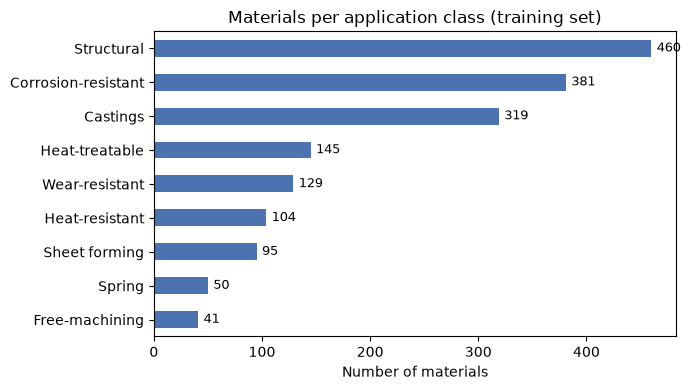

Labels per material: mean 1.23, max 3


In [8]:
mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(train["labels"])
CLASSES = list(mlb.classes_)
print("Classes:", CLASSES)

counts = pd.Series(Y.sum(axis=0), index=CLASSES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("Number of materials"); ax.set_title("Materials per application class (training set)")
for i, v in enumerate(counts.values):
    ax.text(v + 5, i, str(v), va="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "class_counts.png", dpi=150); plt.show()

print("Labels per material: mean %.2f, max %d" % (Y.sum(1).mean(), Y.sum(1).max()))

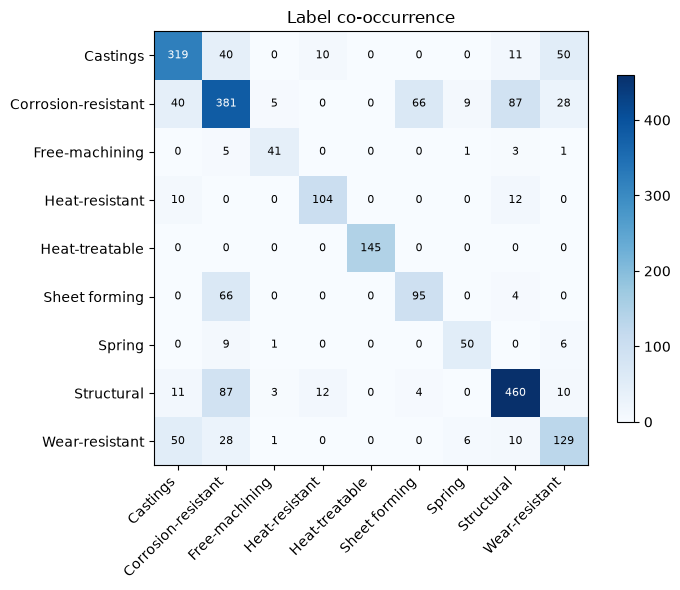

In [9]:
# Label co-occurrence (how often two classes are given to the same material)
co = pd.DataFrame(Y.T @ Y, index=CLASSES, columns=CLASSES)
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(co.values, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, co.values[i, j], ha="center", va="center", fontsize=8,
                color="white" if co.values[i, j] > co.values.max() / 2 else "black")
ax.set_title("Label co-occurrence"); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.savefig(FIG_DIR / "label_cooccurrence.png", dpi=150); plt.show()

## 4. Groups for cross-validation

Group = alloy name without temper suffix (e.g. `6061-T6`, `6061-O` and `Alclad 6061-T6` all map to `6061`).
Every temper of one alloy stays in the same fold, so the model is always tested on **alloys it has never seen**. Without this the score would be inflated (leakage).

**Check the table below.** If two tempers of the same alloy show up as different groups, fix `alloy_group()` in `preprocess.py`.

In [10]:
groups = train["group"].values
print("Training rows:", len(train), "| distinct alloy groups:", train["group"].nunique())

multi = (train.groupby("group")
              .agg(rows=("Material", "size"),
                   family=("family", "first"),
                   materials=("Material", lambda s: " | ".join(sorted(set(map(str, s)))[:4])))
              .sort_values("rows", ascending=False))
multi[multi["rows"] > 1].head(25)

Training rows: 1401 | distinct alloy groups: 994


,rows,family,materials
group,,,
grey cast iron,20,ferrous,Grey cast iron
nodular cast iron,16,ferrous,Nodular cast iron
aluminum alloy 2024,13,aluminium,Aluminum Alloy 2024-O | Aluminum Alloy 2024-T3...
aluminum alloy 2014,11,aluminium,Aluminum Alloy 2014-O | Aluminum Alloy 2014-T4...
aluminum alloy 6061,10,aluminium,Aluminum Alloy 6061-O | Aluminum Alloy 6061-T4...
aluminum alloy 3003,10,aluminium,Aluminum Alloy 3003-H12 | Aluminum Alloy 3003-...
aluminum alloy 3004,10,aluminium,Aluminum Alloy 3004-H32 | Aluminum Alloy 3004-...
steel 45 gost 1050-88,9,ferrous,Steel 45 GOST 1050-88
aluminum alloy 2219,9,aluminium,Aluminum Alloy 2219-O | Aluminum Alloy 2219-T3...


In [11]:
# Non-ferrous sample: confirm the temper suffix is being stripped
nf = train[~train["is_ferrous"]][["Material", "group"]].drop_duplicates()
nf.sample(min(20, len(nf)), random_state=SEED).sort_values("group")

,Material,group
384,Aluminum Alloy 1060-H14,aluminum alloy 1060
386,Aluminum Alloy 1060-H18,aluminum alloy 1060
410,Aluminum Alloy 2017-O,aluminum alloy 2017
344,Aluminum Alloy 242.0,aluminum alloy 242.0
352,Aluminum Alloy 328.0,aluminum alloy 328.0
485,Aluminum Alloy 5052-H38,aluminum alloy 5052
368,Aluminum Alloy 535.0,aluminum alloy 535.0
567,Aluminum Alloy 7050-T73510,aluminum alloy 7050
578,Aluminum Alloy 7178-T651,aluminum alloy 7178
333,Copper Alloy C73500,copper alloy c73500


## 5. Explore the input properties

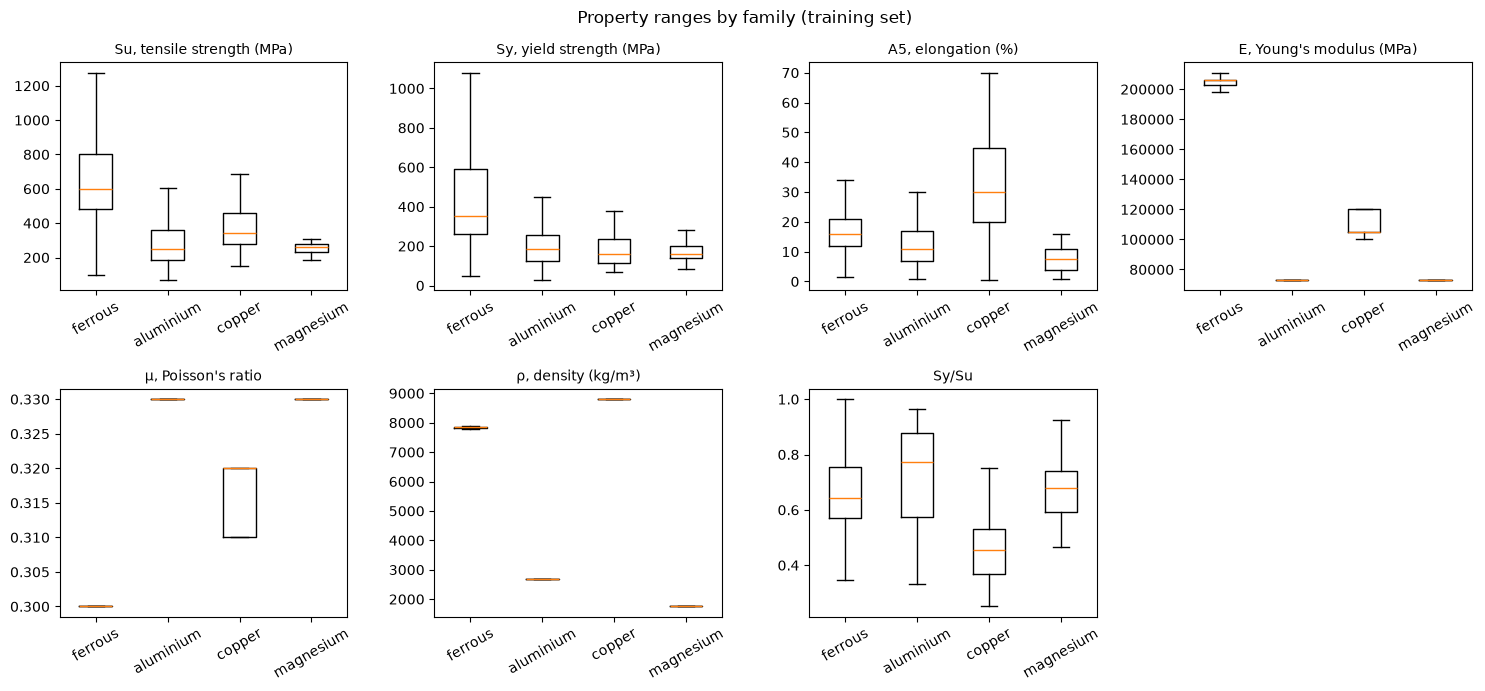

,count,mean,std,min,25%,50%,75%,max
Su,1401.0,553.30,296.20,69.00,338.00,500.00,700.00,1965.00
Sy,1401.0,370.13,259.09,28.00,200.00,295.00,450.00,1896.00
A5,1401.0,18.67,11.70,0.50,11.00,16.00,22.00,70.00
E,1401.0,162788.01,56890.41,73000.00,105000.00,205000.00,206000.00,219000.00
mu,1401.0,0.30,0.02,0.20,0.30,0.30,0.32,0.35
Ro,1401.0,6858.02,2170.98,1750.00,7160.00,7860.00,7860.00,8930.00
Sy_Su,1401.0,0.65,0.17,0.25,0.53,0.64,0.77,1.09


In [12]:
labels_map = {"Su": "Su, tensile strength (MPa)", "Sy": "Sy, yield strength (MPa)",
              "A5": "A5, elongation (%)", "E": "E, Young's modulus (MPa)",
              "mu": "μ, Poisson's ratio", "Ro": "ρ, density (kg/m³)", "Sy_Su": "Sy/Su"}
fams = [f for f in ["ferrous", "aluminium", "copper", "magnesium"] if f in train["family"].unique()]

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    data = [train.loc[train["family"] == f, col].dropna() for f in fams]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(fams) + 1)); ax.set_xticklabels(fams, rotation=30)
    ax.set_title(labels_map[col], fontsize=10)
axes.flat[-1].axis("off")
plt.suptitle("Property ranges by family (training set)"); plt.tight_layout()
plt.savefig(FIG_DIR / "properties_by_family.png", dpi=150); plt.show()

train[NUMERIC_FEATURES].describe().T.round(2)

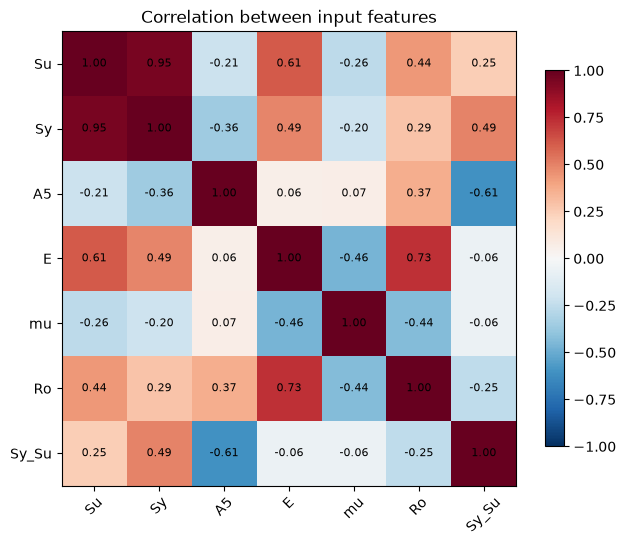

In [13]:
corr = train[NUMERIC_FEATURES].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation between input features"); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_correlation.png", dpi=150); plt.show()

## 6. Models and grouped cross-validation

* **Inputs:** Su, Sy, A5, E, μ, ρ, and derived Sy/Su
* **Target:** 9 application classes, multi-label (a material can belong to several)
* **Models:** Decision Tree, Random Forest, KNN (with scaling), Gradient Boosting (one-vs-rest)
* `class_weight="balanced"` wherever supported, because some classes are rare
* A median imputer sits inside every pipeline for any value still missing; it is fitted on the training folds only

In [14]:
def make_models():
    imp = ("impute", SimpleImputer(strategy="median"))
    return {
        "Decision Tree": lambda: Pipeline([imp, ("clf", DecisionTreeClassifier(
            class_weight="balanced", min_samples_leaf=2, random_state=SEED))]),
        "Random Forest": lambda: Pipeline([imp, ("clf", RandomForestClassifier(
            n_estimators=400, class_weight="balanced", n_jobs=-1, random_state=SEED))]),
        "KNN": lambda: Pipeline([imp, ("scale", StandardScaler()), ("clf", KNeighborsClassifier(
            n_neighbors=5, weights="distance"))]),
        "Gradient Boosting": lambda: Pipeline([imp, ("clf", OneVsRestClassifier(
            HistGradientBoostingClassifier(class_weight="balanced", max_iter=300,
                                           learning_rate=0.05, random_state=SEED)))]),
    }


def get_proba(model, X):
    # Probability of each class being 1, shape (n_samples, n_classes)
    P = model.predict_proba(X)
    if isinstance(P, list):  # native multi-output models return one array per class
        clf = model[-1] if hasattr(model, "steps") else model
        cols = []
        for p, cls in zip(P, clf.classes_):
            cls = list(cls)
            cols.append(p[:, cls.index(1)] if 1 in cls else np.zeros(len(X)))
        return np.column_stack(cols)
    return np.asarray(P)


def grouped_cv(make_model, X, Y, groups, n_splits=N_SPLITS):
    # Out-of-fold predictions: every row is predicted by a model that never saw its alloy
    Y_pred = np.zeros_like(Y)
    Y_prob = np.zeros(Y.shape, dtype=float)
    for tr, te in GroupKFold(n_splits=n_splits).split(X, Y, groups):
        m = make_model()
        m.fit(X.iloc[tr], Y[tr])
        Y_prob[te] = get_proba(m, X.iloc[te])
        Y_pred[te] = (Y_prob[te] >= 0.5).astype(int)
    return Y_pred, Y_prob


def scores(Y_true, Y_pred):
    return {
        "micro_F1": f1_score(Y_true, Y_pred, average="micro", zero_division=0),
        "macro_F1": f1_score(Y_true, Y_pred, average="macro", zero_division=0),
        "exact_match": accuracy_score(Y_true, Y_pred),
        "hamming_loss": hamming_loss(Y_true, Y_pred),
    }


ferrous_mask = train["is_ferrous"].values

In [15]:
FEATURES = feature_columns()        # base: 6 properties + Sy/Su
X = build_X(train, FEATURES)
print("Features:", FEATURES, "| X shape:", X.shape)

results, oof = [], {}
for name, make in make_models().items():
    Y_pred, Y_prob = grouped_cv(make, X, Y, groups)
    oof[name] = (Y_pred, Y_prob)
    for subset, mask in [("All", slice(None)), ("Ferrous", ferrous_mask), ("Non-ferrous", ~ferrous_mask)]:
        results.append({"model": name, "subset": subset, **scores(Y[mask], Y_pred[mask])})
    print(f"done: {name}")

res = pd.DataFrame(results)
comparison = res.pivot(index="model", columns="subset", values=["micro_F1", "macro_F1", "exact_match"]).round(3)
comparison

Features: ['Su', 'Sy', 'A5', 'E', 'mu', 'Ro', 'Sy_Su'] | X shape: (1401, 7)
done: Decision Tree
done: Random Forest
done: KNN
done: Gradient Boosting


micro_F1                     macro_F1                     exact_match                    
subset                 All Ferrous Non-ferrous      All Ferrous Non-ferrous         All Ferrous Non-ferrous
model                                                                                                      
Decision Tree        0.723   0.730       0.714    0.649   0.690       0.501       0.653   0.729       0.490
Gradient Boosting    0.797   0.815       0.776    0.716   0.788       0.549       0.682   0.760       0.515
KNN                  0.750   0.725       0.780    0.674   0.684       0.554       0.651   0.682       0.584
Random Forest        0.751   0.730       0.773    0.701   0.734       0.564       0.611   0.639       0.551

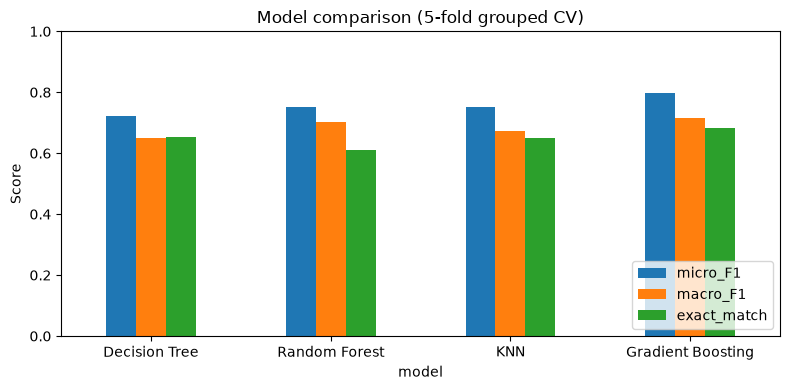

Best model by micro-F1: Gradient Boosting (0.797)


In [16]:
overall = res[res["subset"] == "All"].set_index("model")
fig, ax = plt.subplots(figsize=(8, 4))
overall[["micro_F1", "macro_F1", "exact_match"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Model comparison (5-fold grouped CV)")
ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=150); plt.show()

BEST = overall["micro_F1"].idxmax()
print("Best model by micro-F1:", BEST, f"({overall.loc[BEST, 'micro_F1']:.3f})")

## 7. Do family and heat-treatment condition help?

The plan says to test this rather than assume it. The best model is re-run with:

* base features
* base + one-hot family
* base + one-hot heat-treatment condition
* base + both

**Rule:** keep an extra feature group only if it raises grouped-CV micro-F1 by at least 0.01. Otherwise keep the simpler model.

In [17]:
make_best = make_models()[BEST]
ablation = []
for use_fam, use_ht in [(False, False), (True, False), (False, True), (True, True)]:
    cols = feature_columns(use_family=use_fam, use_ht=use_ht)
    Xa = build_X(train, cols)
    Yp, _ = grouped_cv(make_best, Xa, Y, groups)
    ablation.append({"family": use_fam, "heat_treatment": use_ht, "n_features": len(cols),
                     **scores(Y, Yp),
                     "micro_F1_ferrous": f1_score(Y[ferrous_mask], Yp[ferrous_mask], average="micro"),
                     "micro_F1_nonferrous": f1_score(Y[~ferrous_mask], Yp[~ferrous_mask], average="micro")})
abl = pd.DataFrame(ablation).round(3)
display(abl)

base_f1 = abl.loc[0, "micro_F1"]
best_row = abl.loc[abl["micro_F1"].idxmax()]
if best_row["micro_F1"] - base_f1 >= 0.01:
    USE_FAMILY, USE_HT = bool(best_row["family"]), bool(best_row["heat_treatment"])
else:
    USE_FAMILY, USE_HT = False, False
FEATURES = feature_columns(use_family=USE_FAMILY, use_ht=USE_HT)
X = build_X(train, FEATURES)
print(f"Chosen: family={USE_FAMILY}, heat_treatment={USE_HT} -> {len(FEATURES)} features")

,family,heat_treatment,n_features,micro_F1,macro_F1,exact_match,hamming_loss,micro_F1_ferrous,micro_F1_nonferrous
0,False,False,7,0.797,0.716,0.682,0.055,0.815,0.776
1,True,False,11,0.796,0.708,0.685,0.056,0.814,0.774
2,False,True,15,0.818,0.730,0.710,0.050,0.827,0.806
3,True,True,19,0.815,0.726,0.710,0.050,0.824,0.805


Chosen: family=False, heat_treatment=True -> 15 features


## 8. Light tuning of the best model (grouped CV)

A small grid only: the dataset is small, and a large search would overfit to the CV folds.

In [18]:
GRIDS = {
    "Random Forest": [dict(n_estimators=n, max_depth=d, min_samples_leaf=l)
                      for n in (300, 600) for d in (None, 20) for l in (1, 2)],
    "Decision Tree": [dict(max_depth=d, min_samples_leaf=l) for d in (None, 8, 12) for l in (1, 2, 4)],
    "KNN": [dict(n_neighbors=k, weights=w) for k in (3, 5, 7, 11) for w in ("uniform", "distance")],
    "Gradient Boosting": [dict(estimator__max_depth=d, estimator__learning_rate=lr)
                          for d in (None, 4) for lr in (0.05, 0.1)],
}

def with_params(params):
    def make():
        m = make_models()[BEST]()
        m.named_steps["clf"].set_params(**params)
        return m
    return make

tuning = []
for params in GRIDS.get(BEST, [{}]):
    Yp, _ = grouped_cv(with_params(params), X, Y, groups)
    tuning.append({**params, **scores(Y, Yp)})
tun = pd.DataFrame(tuning).sort_values("micro_F1", ascending=False).round(4)
print(tun.head(8).to_string(index=False))

BEST_PARAMS = {k: (None if pd.isna(v) else v) for k, v in tun.iloc[0].items()
               if k not in ("micro_F1", "macro_F1", "exact_match", "hamming_loss")}
for k, v in BEST_PARAMS.items():           # pandas turns ints into floats
    if isinstance(v, float) and v.is_integer():
        BEST_PARAMS[k] = int(v)
print("\nBest params:", BEST_PARAMS)
make_final = with_params(BEST_PARAMS)

 estimator__max_depth  estimator__learning_rate  micro_F1  macro_F1  exact_match  hamming_loss
                  NaN                      0.05    0.8177    0.7303       0.7102        0.0496
                  NaN                      0.10    0.8169    0.7310       0.7052        0.0494
                  4.0                      0.10    0.8063    0.7197       0.6859        0.0539
                  4.0                      0.05    0.7854    0.7049       0.6231        0.0624

Best params: {'estimator__max_depth': None, 'estimator__learning_rate': 0.05}


## 9. Final evaluation of the chosen model

In [19]:
Y_pred, Y_prob = grouped_cv(make_final, X, Y, groups)

final_scores = {}
for subset, mask in [("All", slice(None)), ("Ferrous", ferrous_mask), ("Non-ferrous", ~ferrous_mask)]:
    final_scores[subset] = {k: round(v, 3) for k, v in scores(Y[mask], Y_pred[mask]).items()}
pd.DataFrame(final_scores).T

,micro_F1,macro_F1,exact_match,hamming_loss
All,0.818,0.730,0.710,0.050
Ferrous,0.827,0.796,0.769,0.038
Non-ferrous,0.806,0.572,0.584,0.074


In [20]:
def per_class_table(Yt, Yp):
    return pd.DataFrame({
        "support": Yt.sum(0),
        "precision": precision_score(Yt, Yp, average=None, zero_division=0),
        "recall": recall_score(Yt, Yp, average=None, zero_division=0),
        "F1": f1_score(Yt, Yp, average=None, zero_division=0),
    }, index=CLASSES).round(3)

per_class = per_class_table(Y, Y_pred)
per_class["F1_ferrous"] = f1_score(Y[ferrous_mask], Y_pred[ferrous_mask], average=None, zero_division=0).round(3)
per_class["F1_nonferrous"] = f1_score(Y[~ferrous_mask], Y_pred[~ferrous_mask], average=None, zero_division=0).round(3)
per_class.sort_values("F1", ascending=False)

,support,precision,recall,F1,F1_ferrous,F1_nonferrous
Castings,319,0.963,0.969,0.966,0.953,0.980
Structural,460,0.864,0.830,0.847,0.850,0.841
Corrosion-resistant,381,0.828,0.845,0.836,0.850,0.827
Heat-treatable,145,0.766,0.814,0.789,0.789,0.000
Sheet forming,95,0.762,0.811,0.786,0.867,0.771
Wear-resistant,129,0.750,0.744,0.747,0.660,0.808
Spring,50,0.700,0.700,0.700,0.955,0.500
Heat-resistant,104,0.548,0.490,0.518,0.592,0.267
Free-machining,41,0.438,0.341,0.384,0.647,0.154


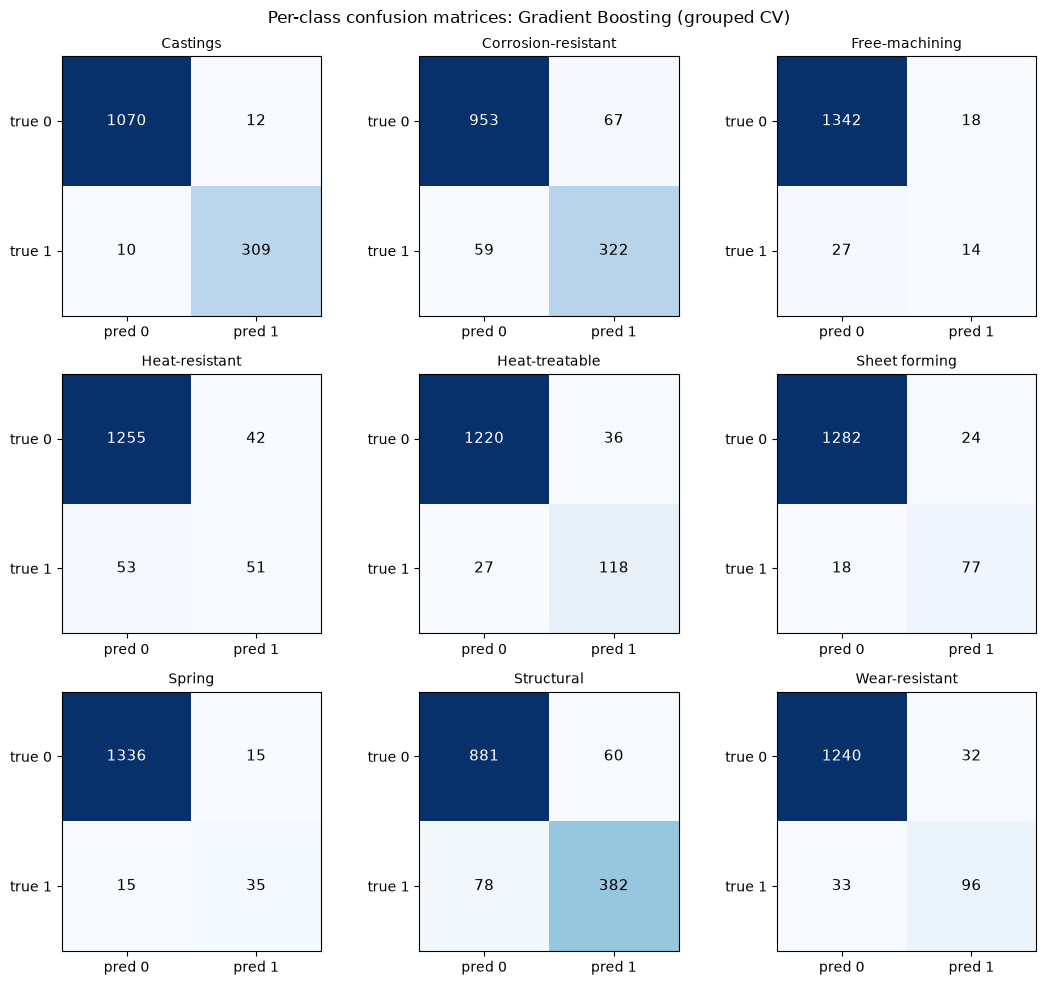

In [21]:
cms = multilabel_confusion_matrix(Y, Y_pred)
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for ax, cm, cls in zip(axes.flat, cms, CLASSES):
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"])
    ax.set_title(cls, fontsize=10)
plt.suptitle(f"Per-class confusion matrices: {BEST} (grouped CV)"); plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=150); plt.show()

**Note on Free-machining.** Free-machining steels get their machinability from added lead or sulphur.
That chemistry barely shows up in strength, elongation, modulus or density, so the model has little to work with and this class scores lowest.
This is a limitation of property-only inputs, not a bug. Adding composition would fix it (future scope).

## 10. Feature importance (Random Forest)

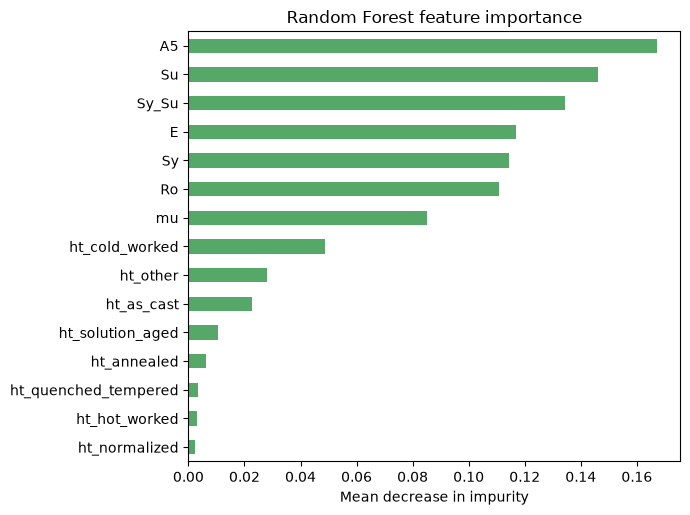

A5                      0.167
Su                      0.146
Sy_Su                   0.135
E                       0.117
Sy                      0.114
Ro                      0.111
mu                      0.085
ht_cold_worked          0.049
ht_other                0.028
ht_as_cast              0.023
ht_solution_aged        0.011
ht_annealed             0.006
ht_quenched_tempered    0.003
ht_hot_worked           0.003
ht_normalized           0.002
dtype: float64

In [22]:
# Fitted on all training rows. Uses the tuned RF if RF won, otherwise a standard RF, so the plot is always available.
if BEST == "Random Forest":
    rf = make_final()
else:
    rf = Pipeline([("impute", SimpleImputer(strategy="median")),
                   ("clf", RandomForestClassifier(n_estimators=400, class_weight="balanced",
                                                  n_jobs=-1, random_state=SEED))])
rf.fit(X, Y)
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, max(3, 0.35 * len(imp))))
imp.plot.barh(ax=ax, color="#55A868")
ax.set_xlabel("Mean decrease in impurity"); ax.set_title("Random Forest feature importance")
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_importance.png", dpi=150); plt.show()
imp.sort_values(ascending=False).round(3)

## 11. Train the final model on all 1,401 rows and score the unlabelled rows

`predict_proba` is used as the **suitability %** shown in the app.

In [23]:
final_model = make_final()
final_model.fit(X, Y)

X_unlab = build_X(unlab, FEATURES)
P_unlab = get_proba(final_model, X_unlab)

def top_classes(p, k=3, min_p=0.5):
    order = np.argsort(p)[::-1][:k]
    return "; ".join(f"{CLASSES[i]} ({p[i]*100:.0f}%)" for i in order if p[i] >= min_p) or "(none >= 50%)"

scored = unlab[["Std", "Material", "Heat treatment", "Su", "Sy", "A5", "E", "mu", "Ro"]].copy()
for i, c in enumerate(CLASSES):
    scored[f"p_{c}"] = P_unlab[:, i].round(3)
scored["predicted_classes"] = [top_classes(p) for p in P_unlab]
scored.to_csv(DATA_DIR / "unlabelled_scored.csv", index=False)
print("Saved", len(scored), "rows -> backend/data/unlabelled_scored.csv")
scored[["Std", "Material", "Heat treatment", "predicted_classes"]].head(10)

Saved 125 rows -> backend/data/unlabelled_scored.csv


,Std,Material,Heat treatment,predicted_classes
0,ANSI,Steel SAE 1015,as-rolled,(none >= 50%)
1,ANSI,Steel SAE 1015,normalized,(none >= 50%)
2,ANSI,Steel SAE 1015,annealed,Corrosion-resistant (65%)
3,ANSI,Steel SAE 1020,as-rolled,(none >= 50%)
4,ANSI,Steel SAE 1020,normalized,(none >= 50%)
5,ANSI,Steel SAE 1020,annealed,(none >= 50%)
6,ANSI,Steel SAE 1022,as-rolled,(none >= 50%)
7,ANSI,Steel SAE 1022,normalized,(none >= 50%)
8,ANSI,Steel SAE 1022,annealed,(none >= 50%)
9,ANSI,Steel SAE 1030,as-rolled,(none >= 50%)


## 12. Save model, label binarizer, feature list and cleaned data

In [24]:
joblib.dump(final_model, MODEL_DIR / "suitability_model.joblib")
joblib.dump(mlb, MODEL_DIR / "label_binarizer.joblib")

meta = {
    "model": BEST,
    "params": BEST_PARAMS,
    "features": FEATURES,
    "use_family": USE_FAMILY,
    "use_heat_treatment": USE_HT,
    "classes": CLASSES,
    "threshold": 0.5,
    "a5_medians": report["a5_medians"],
    "cv": {"method": f"GroupKFold({N_SPLITS}), groups = alloy name without temper",
           "scores": final_scores},
    "n_train": int(len(train)),
    "trained_on": datetime.date.today().isoformat(),
    "sklearn_version": sklearn.__version__,
}
(MODEL_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2))

# Cleaned copy of ALL rows for the engine (original CSV untouched)
keep = [c for c in raw.columns] + ["G_original", "G_fixed", "A5_imputed", "Sy_Su", "ht_cat", "group", "status", "is_ferrous"]
df[[c for c in keep if c in df.columns]].to_csv(DATA_DIR / "materials_clean.csv", index=False)

print("Saved to backend/models/: suitability_model.joblib, label_binarizer.joblib, model_meta.json")
print("Saved backend/data/materials_clean.csv")
print(json.dumps(meta["cv"]["scores"], indent=2))

Saved to backend/models/: suitability_model.joblib, label_binarizer.joblib, model_meta.json
Saved backend/data/materials_clean.csv
{
  "All": {
    "micro_F1": 0.818,
    "macro_F1": 0.73,
    "exact_match": 0.71,
    "hamming_loss": 0.05
  },
  "Ferrous": {
    "micro_F1": 0.827,
    "macro_F1": 0.796,
    "exact_match": 0.769,
    "hamming_loss": 0.038
  },
  "Non-ferrous": {
    "micro_F1": 0.806,
    "macro_F1": 0.572,
    "exact_match": 0.584,
    "hamming_loss": 0.074
  }
}


In [25]:
# Sanity check: reload from disk and predict suitability for 3 known materials
m = joblib.load(MODEL_DIR / "suitability_model.joblib")
lb = joblib.load(MODEL_DIR / "label_binarizer.joblib")
fe = json.loads((MODEL_DIR / "model_meta.json").read_text())["features"]

sample = train.groupby("family").head(1)
P = get_proba(m, build_X(sample, fe))
out = pd.DataFrame((P * 100).round(0), columns=lb.classes_, index=sample["Material"])
out.insert(0, "true labels", sample["app_classes"].values)
out

,true labels,Castings,Corrosion-resistant,Free-machining,Heat-resistant,Heat-treatable,Sheet forming,Spring,Structural,Wear-resistant
Material,,,,,,,,,,
Steel SAE 30201,Corrosion-resistant,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
High-Copper Alloy C81300,Castings,100.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
Aluminum Alloy 201.0,Castings,100.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
Magnesium Alloy AM100A-T61,Castings,100.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## 13. Summary (fill in after running)

| | micro-F1 | macro-F1 | exact match |
|---|---|---|---|
| All | | | |
| Ferrous | | | |
| Non-ferrous | | | |

* Best model: …
* Family / heat-treatment features kept? … (with the ablation numbers)
* Weakest class: Free-machining (lead/sulphur content is not visible in mechanical properties)
* Grouped CV by alloy, so all scores are on unseen alloys

**Next step:** `backend/engine/` uses `suitability_model.joblib` + `model_meta.json` to score candidates, then applies TOPSIS and the price layer.